# Telecom customer churn prediction
## Assignment solution: logistic regression
**Objective:** estimate churn probability, classify customers and interpret retention tradeoffs.

**Input mismatch:** `Position_Salaries.csv` has only Position, Level and Salary (10 rows). It has no customer attributes or churn target, so it cannot answer `7_10_26_task.txt`. This solution uses the public Telco Customer Churn dataset explicitly linked in that task. The salary file is preserved unchanged.

**Source:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn (downloaded 2026-10-08). Local copy: `data/WA_Fn-UseC_-Telco-Customer-Churn.csv`. The task's Google Drive link was not accessible; the Kaggle download was used directly.

Run all cells from this project folder. Dependencies: pandas, numpy, scikit-learn, matplotlib, jupyter/ipykernel. Salary currency is not specified in the supplied files; charge values below are reported in dataset units.

In [1]:
from pathlib import Path
import json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, fbeta_score, roc_auc_score, average_precision_score, brier_score_loss,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    raise FileNotFoundError('Run this notebook from the folder containing data/.')
OUT = ROOT / 'output'
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
DATA = ROOT / 'data/WA_Fn-UseC_-Telco-Customer-Churn.csv'
df = pd.read_csv(DATA)
print('Dataset shape:', df.shape)
print('SHA256:', hashlib.sha256(DATA.read_bytes()).hexdigest())
print('Python:', platform.python_version(), 'pandas:', pd.__version__, 'sklearn:', sklearn.__version__)
display(df.head())

Dataset shape: (7043, 21)
SHA256: 88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a
Python: 3.12.3 pandas: 2.2.3 sklearn: 1.9.0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Understand and validate the data
Each row describes one customer. `Churn` is the target (Yes=1, No=0). `customerID` identifies records and is excluded from the model.

Inputs cover demographics (gender, SeniorCitizen, Partner, Dependents), relationship length (tenure), subscribed services (PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies), account terms (Contract, PaperlessBilling, PaymentMethod) and charges (MonthlyCharges, TotalCharges).

Contract and tenure may reflect commitment; service choices and charges may relate to customer experience and price. These are candidate predictive associations, not causal conclusions. Gender and senior status are retained for this classroom model; deployment would require a review of subgroup performance and feature suitability.

Originally missing cells: 0
Missing TotalCharges after numeric conversion: 11
Duplicate rows: 0


,dtype,missing,unique
customerID,object,0,7043
gender,object,0,2
SeniorCitizen,int64,0,2
Partner,object,0,2
Dependents,object,0,2
tenure,int64,0,73
PhoneService,object,0,2
MultipleLines,object,0,3
InternetService,object,0,3
OnlineSecurity,object,0,3


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7032.00
mean,32.37,64.76,2283.30
std,24.56,30.09,2266.77
min,0.00,18.25,18.80
25%,9.00,35.50,401.45
50%,29.00,70.35,1397.48
75%,55.00,89.85,3794.74
max,72.00,118.75,8684.80


,Customers
Churn,
No,5174
Yes,1869


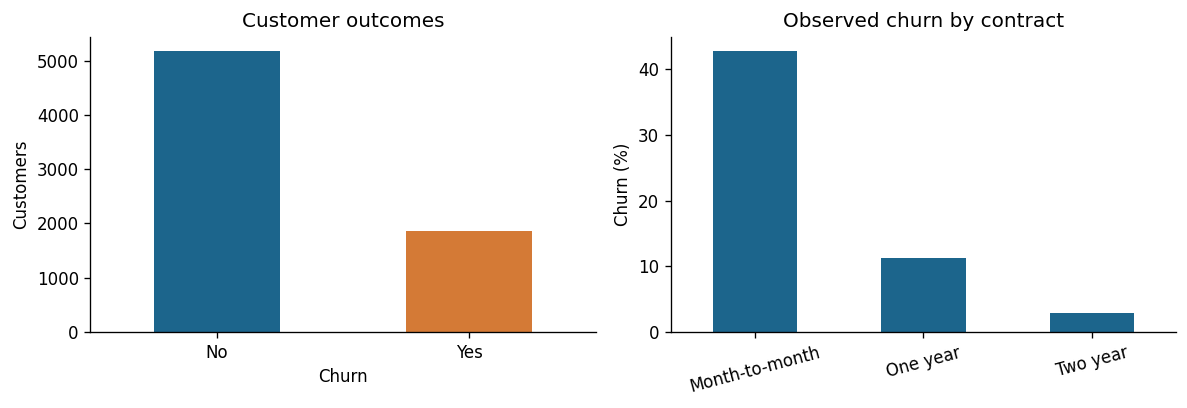

In [2]:
assert df['customerID'].is_unique, 'Duplicate customer IDs require investigation'
assert set(df.Churn.unique()) == {'Yes', 'No'}
raw_missing = int(df.isna().sum().sum())
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Originally missing cells:', raw_missing)
print('Missing TotalCharges after numeric conversion:', df.TotalCharges.isna().sum())
print('Duplicate rows:', df.duplicated().sum())
display(pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum(),
                      'unique': df.nunique()}))
display(df[['tenure', 'MonthlyCharges', 'TotalCharges']].describe().round(2))
display(df.Churn.value_counts().rename_axis('Churn').to_frame('Customers'))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
df.Churn.value_counts().reindex(['No', 'Yes']).plot.bar(ax=ax[0], color=['#1c658c','#d47a36'], rot=0)
ax[0].set(title='Customer outcomes', ylabel='Customers', xlabel='Churn')
df.assign(churn_flag=df.Churn.eq('Yes')).groupby('Contract').churn_flag.mean().mul(100).plot.bar(ax=ax[1], color='#1c658c', rot=15)
ax[1].set(title='Observed churn by contract', ylabel='Churn (%)', xlabel='')
fig.tight_layout()
fig.savefig(OUT / 'data_overview.png', bbox_inches='tight')
plt.show()

## 2. Split data and prepare features
Use a stratified 60% training / 20% validation / 20% test split with random seed 42. Training fits preprocessing and model parameters. Validation selects a threshold. The test set stays untouched until final evaluation.

Numeric missing values are replaced with training medians and numeric inputs are standardized. Categorical values are imputed with the training mode and one-hot encoded, dropping a reference category. Unknown categories are ignored by the encoder. All learned preprocessing is inside the pipeline to prevent leakage. No oversampling or class weighting is used, preserving the observed class balance.

Logistic regression calculates `P(churn) = 1 / (1 + exp(-z))`, where `z` is an intercept plus weighted prepared features. Probabilities are model estimates; calibration is assessed only approximately here.

In [3]:
X = df.drop(columns=['customerID', 'Churn'])
y = df.Churn.map({'No': 0, 'Yes': 1})
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=42)
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
cat_cols = [col for col in X.columns if col not in num_cols]
preprocess = ColumnTransformer([
    ('numeric', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), num_cols),
    ('category', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                          ('encode', OneHotEncoder(drop='first', handle_unknown='ignore'))]), cat_cols)])
model = Pipeline([('preprocess', preprocess),
                  ('classifier', LogisticRegression(C=1.0, max_iter=2000, solver='lbfgs', random_state=42))])
model.fit(X_train, y_train)
splits = pd.DataFrame([{'Split': name, 'Customers': len(target), 'Churners': int(target.sum()),
                       'Churn rate': target.mean()} for name, target in
                      [('Training', y_train), ('Validation', y_val), ('Test', y_test)]])
display(splits)
print('Solver iterations:', model.named_steps['classifier'].n_iter_)

,Split,Customers,Churners,Churn rate
0,Training,4225,1121,0.265325
1,Validation,1409,374,0.265436
2,Test,1409,374,0.265436


Solver iterations: [47]


## 3. Select a retention threshold using validation data
A customer is flagged when the predicted churn probability is at least the threshold. Compare the default 0.50 with a threshold selected to maximize validation F2 over 0.10 to 0.80 in steps of 0.01. F2 emphasizes recall more than precision, reflecting a provisional preference to miss fewer churners. It does not encode an actual financial cost ratio. Ties select the larger threshold to reduce unnecessary offers. The selected model is not refitted after choosing the threshold.

In [4]:
val_prob = model.predict_proba(X_val)[:, 1]
thresholds = np.round(np.arange(0.10, 0.801, 0.01), 2)
threshold_table = pd.DataFrame([{'Threshold': t, 'F2': fbeta_score(y_val, val_prob >= t, beta=2),
    'Precision': precision_score(y_val, val_prob >= t, zero_division=0),
    'Recall': recall_score(y_val, val_prob >= t)} for t in thresholds])
selected = threshold_table.sort_values(['F2', 'Threshold'], ascending=[False, False]).iloc[0]
threshold = float(selected.Threshold)
print(f'Selected threshold: {threshold:.2f}')
display(threshold_table.sort_values(['F2', 'Threshold'], ascending=False).head(5))

Selected threshold: 0.13


,Threshold,F2,Precision,Recall
3,0.13,0.737138,0.417381,0.911765
2,0.12,0.735420,0.410287,0.917112
4,0.14,0.734845,0.422836,0.901070
6,0.16,0.733540,0.432855,0.887701
7,0.17,0.732087,0.438083,0.879679


## 4. Evaluate once on unseen test customers
**TP:** churners correctly flagged. **FN:** churners missed. **FP:** non-churners wrongly flagged. **TN:** non-churners correctly classified. Precision measures how many flagged customers actually churn; recall measures how many churners are found. ROC AUC measures ranking across thresholds; average precision summarizes precision-recall ranking. Lower Brier score means better probability accuracy. Accuracy alone can hide missed churners because non-churn customers are the majority.

,Model,Threshold,Accuracy,Precision,Recall,F1,F2,ROC AUC,Average precision,Brier,TN,FP,FN,TP
0,Always stay,NaN,0.7346,0.0000,0.0000,0.0000,0.0000,0.500,0.2654,0.1950,1035,0,374,0
1,Logistic / default,0.50,0.8027,0.6519,0.5508,0.5971,0.5684,0.843,0.6348,0.1376,925,110,168,206
2,Logistic / retention,0.13,0.6565,0.4316,0.9278,0.5891,0.7543,0.843,0.6348,0.1376,578,457,27,347


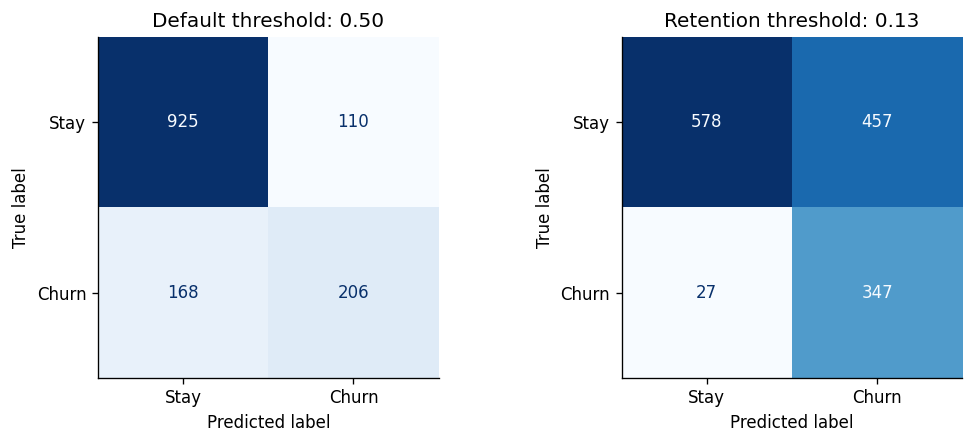

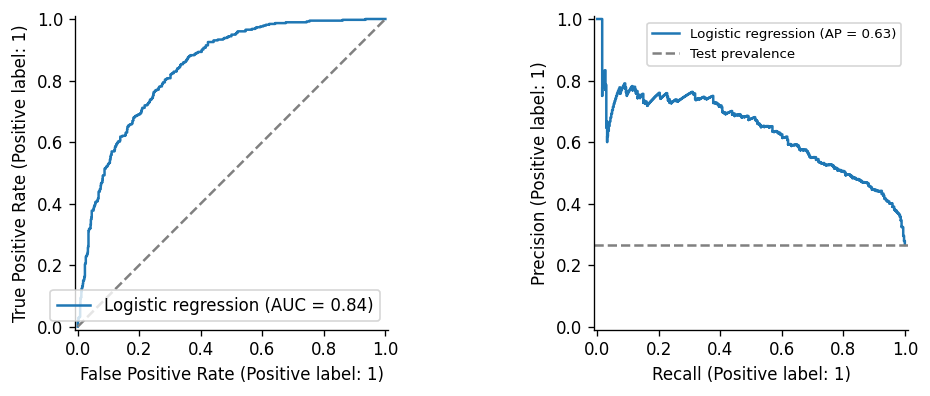

In [5]:
test_prob = model.predict_proba(X_test)[:, 1]
def evaluate(label, pred, prob, cutoff=None):
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    return {'Model': label, 'Threshold': cutoff, 'Accuracy': accuracy_score(y_test, pred),
            'Precision': precision_score(y_test, pred, zero_division=0), 'Recall': recall_score(y_test, pred),
            'F1': f1_score(y_test, pred, zero_division=0), 'F2': fbeta_score(y_test, pred, beta=2, zero_division=0),
            'ROC AUC': roc_auc_score(y_test, prob), 'Average precision': average_precision_score(y_test, prob),
            'Brier': brier_score_loss(y_test, prob), 'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp)}
results = pd.DataFrame([
    evaluate('Always stay', np.zeros(len(y_test), dtype=int), np.full(len(y_test), y_train.mean())),
    evaluate('Logistic / default', test_prob >= 0.5, test_prob, 0.5),
    evaluate('Logistic / retention', test_prob >= threshold, test_prob, threshold)])
display(results.round(4))
results.to_csv(OUT / 'evaluation_metrics.csv', index=False)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
for a, cutoff, title in zip(ax, [0.5, threshold], ['Default threshold', 'Retention threshold']):
    ConfusionMatrixDisplay.from_predictions(y_test, test_prob >= cutoff, labels=[0,1],
        display_labels=['Stay', 'Churn'], colorbar=False, cmap='Blues', ax=a)
    a.set_title(f'{title}: {cutoff:.2f}')
fig.tight_layout()
fig.savefig(OUT / 'confusion_matrices.png', bbox_inches='tight')
plt.show()
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
RocCurveDisplay.from_predictions(y_test, test_prob, ax=ax[0], name='Logistic regression')
ax[0].plot([0,1], [0,1], '--', color='gray')
PrecisionRecallDisplay.from_predictions(y_test, test_prob, ax=ax[1], name='Logistic regression')
ax[1].axhline(y_test.mean(), linestyle='--', color='gray', label='Test prevalence')
ax[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / 'ranking_curves.png', bbox_inches='tight')
plt.show()

## 5. Predict outcomes for unseen records
The first ten held-out test records below were never used to fit the model or choose the threshold. True outcomes are displayed only for comparison. `predict_customers` can also score new rows containing the same 19 input columns; customer IDs and any supplied outcomes are not used as predictors.

In [6]:
def predict_customers(records, cutoff=threshold):
    missing = set(X.columns) - set(records.columns)
    if missing:
        raise ValueError(f'Missing required features: {sorted(missing)}')
    prepared = records.loc[:, X.columns].copy()
    prepared['TotalCharges'] = pd.to_numeric(prepared['TotalCharges'], errors='coerce')
    probability = model.predict_proba(prepared)[:, 1]
    return pd.DataFrame({'Churn probability': probability,
        'Prediction': np.where(probability >= cutoff, 'Likely to churn', 'Likely to stay')}, index=records.index)
predictions = predict_customers(X_test)
predictions.insert(0, 'customerID', df.loc[X_test.index, 'customerID'])
predictions['Actual churn'] = y_test.map({0: 'No', 1: 'Yes'})
predictions.to_csv(OUT / 'unseen_customer_predictions.csv', index=False)
display(predictions.head(10).style.format({'Churn probability': '{:.1%}'}))

,customerID,Churn probability,Prediction,Actual churn
437,4376-KFVRS,4.0%,Likely to stay,No
2280,2754-SDJRD,70.2%,Likely to churn,No
2235,9917-KWRBE,6.1%,Likely to stay,No
4460,0365-GXEZS,38.0%,Likely to churn,No
3761,9385-NXKDA,1.8%,Likely to stay,No
5748,4686-UXDML,61.6%,Likely to churn,No
3568,2227-JRSJX,45.1%,Likely to churn,No
2976,4830-FAXFM,12.3%,Likely to stay,No
5928,1830-IPXVJ,0.2%,Likely to stay,No
1639,4690-LLKUA,37.0%,Likely to churn,Yes


## 6. Interpret feature associations
Positive coefficients raise modeled churn log-odds, conditional on other inputs; negative coefficients lower them. Numeric coefficients refer to one training standard deviation. Categorical coefficients compare against the omitted reference category. Regularization and correlated charge/tenure inputs affect their size, so coefficients do not establish causes or prove which intervention will prevent churn.

In [7]:
feature_names = model.named_steps['preprocess'].get_feature_names_out()
coef = pd.Series(model.named_steps['classifier'].coef_[0], index=feature_names)
strongest = coef.reindex(coef.abs().sort_values(ascending=False).head(10).index)
display(strongest.rename('Coefficient').to_frame().round(3))
ret = results.iloc[2]
default = results.iloc[1]
display(Markdown(f"""## 7. Business conclusions
At the validation-selected threshold **{threshold:.2f}**, the test set contains **{int(ret.TP)} correctly identified churners**, **{int(ret.FP)} non-churners wrongly flagged**, **{int(ret.FN)} missed churners** and **{int(ret.TN)} correctly identified non-churners**.

Recall is **{ret.Recall:.1%}** and precision is **{ret.Precision:.1%}**. Compared with 0.50, the retention threshold detects **{int(ret.TP-default.TP)} additional churners** and produces **{int(ret.FP-default.FP)} additional false alarms**. It flags **{int(ret.TP+ret.FP)}** of **{len(y_test)}** customers.

For inexpensive outreach, wrongly flagging a loyal customer may be preferable to missing a departing customer, because a missed churner can mean lost future revenue and acquisition expense. However, offers to loyal customers cost money and can cause unnecessary discounting. Which error is worse depends on offer cost, customer value, contact capacity and how effectively an offer prevents churn. No cost data are supplied, so this threshold is provisional, not a proven profit optimum.

An illustrative error-cost expression is `FP × cost_of_unnecessary_offer + FN × cost_of_missed_churn`. Actual campaign value must also account for offer costs to true positives and treatment effectiveness; a detected churner is not automatically a retained customer.

**One improvement:** collect recent, time-stamped customer observations and validate on a later time period. This better tests reliability for future customers than a random split from one dataset. Tune any revised model and threshold using development data, preserving a fresh final test set.

**Limitations:** this public sample does not establish performance for a specific telecom company. No temporal holdout, confidence intervals or subgroup audit is included. Brier score is a probability-error summary, not proof of calibration; real-world reliability needs further validation.
"""))
summary = {'rows': len(df), 'columns': len(df.columns), 'missing_total_charges': int(df.TotalCharges.isna().sum()),
           'churners': int(y.sum()), 'threshold': threshold, 'validation_f2': float(selected.F2),
           'splits': splits.to_dict(orient='records'), 'metrics': results.to_dict(orient='records'),
           'examples': predictions.head(10).to_dict(orient='records'),
           'coefficients': strongest.to_dict(), 'sha256': hashlib.sha256(DATA.read_bytes()).hexdigest()}
(OUT / 'analysis_summary.json').write_text(json.dumps(summary, indent=2))

,Coefficient
category__Contract_Two year,-1.491
numeric__tenure,-1.307
category__InternetService_Fiber optic,1.038
category__Contract_One year,-0.727
numeric__TotalCharges,0.583
category__PhoneService_Yes,-0.514
category__OnlineSecurity_Yes,-0.372
category__MultipleLines_Yes,0.369
category__StreamingTV_Yes,0.358
category__PaymentMethod_Electronic check,0.356


## 7. Business conclusions
At the validation-selected threshold **0.13**, the test set contains **347 correctly identified churners**, **457 non-churners wrongly flagged**, **27 missed churners** and **578 correctly identified non-churners**.

Recall is **92.8%** and precision is **43.2%**. Compared with 0.50, the retention threshold detects **141 additional churners** and produces **347 additional false alarms**. It flags **804** of **1409** customers.

For inexpensive outreach, wrongly flagging a loyal customer may be preferable to missing a departing customer, because a missed churner can mean lost future revenue and acquisition expense. However, offers to loyal customers cost money and can cause unnecessary discounting. Which error is worse depends on offer cost, customer value, contact capacity and how effectively an offer prevents churn. No cost data are supplied, so this threshold is provisional, not a proven profit optimum.

An illustrative error-cost expression is `FP × cost_of_unnecessary_offer + FN × cost_of_missed_churn`. Actual campaign value must also account for offer costs to true positives and treatment effectiveness; a detected churner is not automatically a retained customer.

**One improvement:** collect recent, time-stamped customer observations and validate on a later time period. This better tests reliability for future customers than a random split from one dataset. Tune any revised model and threshold using development data, preserving a fresh final test set.

**Limitations:** this public sample does not establish performance for a specific telecom company. No temporal holdout, confidence intervals or subgroup audit is included. Brier score is a probability-error summary, not proof of calibration; real-world reliability needs further validation.


4082